# TPOT classifier with SentenceTransformer embeddings


In [1]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

sys.path.insert(0, str(Path.cwd()))

from data import make_groups
from evaluation import baseline_predictions, evaluate, split_data

data = pd.read_csv("../data/processed/headlines_with_embedic_large.csv")
data["group"] = make_groups(data)
labels = sorted(data["label"].unique())
embeddings = np.stack(data["embedding"].map(json.loads).to_numpy()).astype(np.float32)
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]
X_train = embeddings[train_indices]
X_test = embeddings[test_indices]

majority_label, baseline = baseline_predictions(train["label"], len(test))
print(f"majority baseline: {majority_label}")
display(
    pd.DataFrame(evaluate(test["label"], baseline, labels)["report"])
    .T[["precision", "recall", "f1-score", "support"]]
    .round(3)
)
print(f"Embedding train: {X_train.shape}; test: {X_test.shape}")

majority baseline: vilifying_opponents


,precision,recall,f1-score,support
nothing,0.000,0.000,0.000,22.000
personality_cult,0.000,0.000,0.000,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.000,0.000,0.000,20.000
vilifying_opponents,0.538,1.000,0.700,71.000
accuracy,0.538,0.538,0.538,0.538
macro avg,0.108,0.200,0.140,132.000
weighted avg,0.289,0.538,0.376,132.000


Embedding train: (323, 1024); test: (132, 1024)


In [2]:
from tpot import TPOTClassifier

est = TPOTClassifier(
    search_space="linear",
    scorers=["balanced_accuracy"],
    cv=3,
    n_jobs=5,
    max_time_mins=15,
    max_eval_time_mins=5,
    verbose=2
)
est.fit(X_train, train["label"])
print(est.fitted_pipeline_)

/Users/jtakalai/python/propaganda-radar/regression/.venv/lib/python3.13/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/jtakalai/python/propaganda-radar/regression/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jtakalai/python/propaganda-radar/regression/.venv/lib/python3.13/site-packages/tpot/tpot_estimator/estimator.py:537: UserWarning: Labels are not encoded as ints from 0 to N. For compatibility with some classifiers such as sklearn, TPOT has encoded y with the sklearn LabelEncoder. When using pipelines outside the main TPOT esti

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('variancethreshold',
                 VarianceThreshold(threshold=0.0402371502621)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('sgdclassifier',
                 SGDClassifier(alpha=1.10993736e-05, class_weight='balanced',
                               eta0=0.2716573552632, fit_intercept=np.True_,
                               l1_ratio=0.57220

Accuracy: TPOT 0.788 | majority baseline 0.538


,precision,recall,f1-score,support
nothing,0.615,0.727,0.667,22.000
personality_cult,0.375,0.429,0.400,7.000
vilifying_eu,0.667,0.833,0.741,12.000
vilifying_neighbours,0.692,0.900,0.783,20.000
vilifying_opponents,1.000,0.803,0.891,71.000
accuracy,0.788,0.788,0.788,0.788
macro avg,0.670,0.738,0.696,132.000
weighted avg,0.826,0.788,0.797,132.000


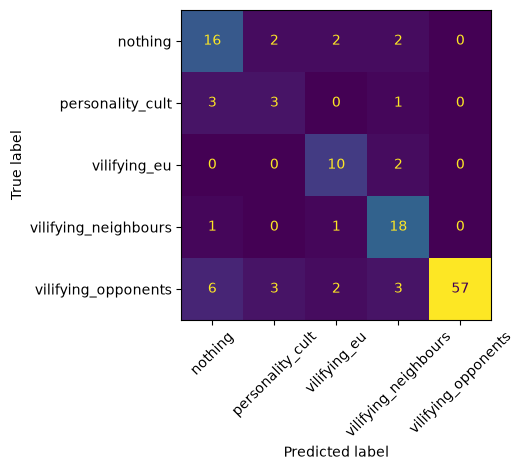

In [3]:
encoded_predictions = est.predict(X_test).astype(int)
predictions = est.label_encoder_.inverse_transform(encoded_predictions)
metrics = evaluate(test["label"], predictions, labels)
baseline_accuracy = evaluate(test["label"], baseline, labels)["report"]["accuracy"]
print(
    f"Accuracy: TPOT {metrics['report']['accuracy']:.3f} "
    f"| majority baseline {baseline_accuracy:.3f}"
)
display(
    pd.DataFrame(metrics["report"]).T[
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

ConfusionMatrixDisplay(
    metrics["confusion_matrix"],
    display_labels=labels,
).plot(xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

In [4]:
pipeline = est.fitted_pipeline_

print(pipeline)
print("\nPipeline steps:")
for name, step in pipeline.steps:
    print(f"{name}: {step}")

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('variancethreshold',
                 VarianceThreshold(threshold=0.0402371502621)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('sgdclassifier',
                 SGDClassifier(alpha=1.10993736e-05, class_weight='balanced',
                               eta0=0.2716573552632, fit_intercept=np.True_,
                               l1_ratio=0.57220